# Proyecto 3 · Visualización I · Equipo Castro–Pulido
## Sostener un hogar sin respaldo: informalidad laboral de las jefas de hogar con hijos menores

**David Castro y Felipe Pulido** · Universidad Externado de Colombia

Continuación del Proyecto 1. Misma fuente (GEIH 2026, enero–junio) y **la misma definición de
informalidad**: la función `fxInformalidadDANE` del modelo de Power BI se tradujo a Python
línea por línea, y la sección 10 verifica que las cifras coincidan con el dashboard.

Lo que cambia es el destinatario. El Proyecto 1 hablaba a un decisor de política pública;
este trabajo habla a las propias mujeres de las que tratan los datos.

Este cuaderno no repite el dashboard. Power BI responde *dónde* está el problema. Aquí se
responden dos cosas que el tablero no muestra: **cuánto se gana frente al salario mínimo** y
**cómo cambia el tipo de empleo según la zona**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

plt.rcParams["text.parse_math"] = False

RUTA = Path("data/raw")      # carpeta 01_datos_GEIH_2026 del Proyecto 1
SALIDA = Path("outputs")
SALIDA.mkdir(parents=True, exist_ok=True)

SMMLV_2026 = 1_750_905       # Decreto 1469 de 2025
MESES = 6                    # enero a junio
MIN_CASOS = 30               # mínimo de registros sin ponderar para graficar un grupo

NARANJA, AZUL, GRIS = "#EB6834", "#2A78D6", "#8A8A8A"   # paleta del Proyecto 1

LLAVES = ["DIRECTORIO", "SECUENCIA_P", "HOGAR", "ORDEN", "MES"]
HOGAR = ["DIRECTORIO", "SECUENCIA_P", "HOGAR", "MES"]
W = "FEX_C18"

## 1. Carga
Las mismas variables que selecciona Power Query, con separador «;» y codificación Windows-1252.

In [2]:
COLS_OC = LLAVES + ["PER", "CLASE", "DPTO", W, "OCI", "P6430", "P6765", "P3045S1", "P3046",
                    "P3065", "P3066", "P3067", "P3067S1", "P3067S2", "P6775", "P3068",
                    "P3069", "P6450", "P6920", "P6930", "P6940", "RAMA2D_R4", "OFICIO_C8",
                    "INGLABO"]
COLS_CG = LLAVES + ["P3271", "P6040", "P6050", "P6100", "P6110"]


def leer_modulo(carpeta: Path, ocupados: bool) -> pd.DataFrame:
    cols = COLS_OC if ocupados else COLS_CG
    partes = []
    for mes in sorted(p for p in carpeta.iterdir() if p.is_dir()):
        archivos = [f for f in mes.iterdir()
                    if f.suffix.upper() == ".CSV" and (("Ocupados" in f.name) == ocupados)]
        if not archivos:
            raise FileNotFoundError(f"Falta un módulo en {mes.name}")
        partes.append(pd.read_csv(archivos[0], sep=";", encoding="latin-1",
                                  usecols=lambda c: c in cols, low_memory=False))
    return pd.concat(partes, ignore_index=True)


ocupados = leer_modulo(RUTA, ocupados=True)
personas = leer_modulo(RUTA, ocupados=False)
print(f"Ocupados: {len(ocupados):,} · Personas: {len(personas):,}")

Ocupados: 177,195 · Personas: 401,950


## 2. Hijos menores por hogar y cruce de módulos
Los hijos se cuentan sobre todas las personas del hogar, no solo sobre las ocupadas.

In [3]:
personas["hijo_menor"] = ((personas.P6050 == 3) & (personas.P6040 < 18)).astype(int)
hijos = (personas.groupby(HOGAR, as_index=False)["hijo_menor"].sum()
                 .rename(columns={"hijo_menor": "hijos_menores"}))

datos = (ocupados
         .merge(personas[LLAVES + ["P3271", "P6050", "P6100", "P6110"]], on=LLAVES,
                how="left", validate="one_to_one")
         .merge(hijos, on=HOGAR, how="left"))
datos["hijos_menores"] = datos.hijos_menores.fillna(0).astype(int)

assert datos.P3271.isna().sum() == 0, "Hay ocupados sin datos personales: revise las llaves."
print(f"Cruce correcto: {len(datos):,} ocupados, ninguno sin pareja.")

Cruce correcto: 177,195 ocupados, ninguno sin pareja.


## 3. Informalidad: `fxInformalidadDANE` traducida a Python

Réplica de la función M del Proyecto 1, que a su vez traduce la sintaxis oficial del DANE
(anexo *Empleo informal y seguridad social*, GEIH marco 2018).

Tres reglas, en este orden:

1. **Empleadas del gobierno** son formales; **sin remuneración** y **«otro»** son informales.
2. **Independientes** (cuenta propia y patronas): decide el sector de la unidad económica,
   según registro mercantil, contabilidad, tamaño y oficio.
3. **Asalariadas** (particular, doméstica, jornalera): formales solo si tienen **salud
   contributiva pagada por el empleador y pensión**. Las dos condiciones, no una.

En M, `null` vuelve falsa cualquier comparación. Aquí se replica con máscaras que exigen
`notna()` antes de comparar.

In [4]:
def informalidad_dane(df: pd.DataFrame) -> pd.Series:
    """1 = ocupado informal, 0 = formal. Réplica de fxInformalidadDANE."""
    n = len(df)
    col = {c: df[c].to_numpy() for c in df.columns}
    falta = pd.isna

    def eq(a, v):   return (~falta(a)) & (a == v)
    def ins(a, vs): return (~falta(a)) & np.isin(a, vs)
    def ge(a, v):   return (~falta(a)) & (a >= v)
    def le(a, v):   return (~falta(a)) & (a <= v)
    def lt(a, v):   return (~falta(a)) & (a < v)

    P6430, P6765 = col["P6430"], col["P6765"]
    P3045S1, P3046 = col["P3045S1"], col["P3046"]
    P3065, P3066 = col["P3065"], col["P3066"]
    P3067, P3067S1, P3067S2 = col["P3067"], col["P3067S1"], col["P3067S2"]
    P6775, P3068, P3069 = col["P6775"], col["P3068"], col["P3069"]
    P6100, P6110, P6450 = col["P6100"], col["P6110"], col["P6450"]
    P6920, P6930, P6940 = col["P6920"], col["P6930"], col["P6940"]
    Rama = col["RAMA2D_R4"]

    # OFICIO_C8: los dos primeros dígitos (grupo principal de la CIUO).
    oficio = pd.to_numeric(pd.Series(col["OFICIO_C8"]).astype("string").str.slice(0, 2),
                           errors="coerce").to_numpy()
    umbral = col["PER"] - 1          # registro renovado el año anterior o el actual

    indep = ins(P6430, [4, 5])
    con_negocio = indep & eq(P6765, 7)
    sin_negocio = indep & ~eq(P6765, 7)
    asal_17 = ins(P6430, [1, 7])

    # --- Sector de la unidad económica: 1 formal, 0 informal, nan sin información ---
    sector = np.full(n, np.nan)
    resuelto = eq(P6430, 3)          # doméstico: el sector no aplica (null en M)

    def rama(cond, valor):
        """Primera coincidencia gana, como el if/else encadenado de M."""
        np.putmask(sector, falta(sector) & ~resuelto & cond, valor)

    rama(eq(P6430, 6), 0)
    rama(ins(Rama, [84, 99]), 1)
    rama(eq(P6430, 8), 0)
    rama(eq(P6430, 2), 1)
    rama(asal_17 & eq(P3045S1, 1), 1)
    rama(asal_17 & ins(P3045S1, [2, 9]) & eq(P3046, 1), 1)
    rama(asal_17 & ins(P3045S1, [2, 9]) & eq(P3046, 2), 0)
    rama(asal_17 & ins(P3045S1, [2, 9]) & eq(P3046, 9) & ge(P3069, 4), 1)
    rama(asal_17 & ins(P3045S1, [2, 9]) & eq(P3046, 9) & le(P3069, 3), 0)
    rama(sin_negocio & eq(P3065, 1), 1)
    rama(sin_negocio & ins(P3065, [2, 9]) & eq(P3066, 1), 1)
    rama(sin_negocio & ins(P3065, [2, 9]) & eq(P3066, 2), 0)
    rama(sin_negocio & eq(P6430, 5) & ins(P3065, [2, 9]) & eq(P3066, 9) & ge(P3069, 4), 1)
    rama(sin_negocio & eq(P6430, 5) & ins(P3065, [2, 9]) & eq(P3066, 9) & le(P3069, 3), 0)
    rama(sin_negocio & eq(P6430, 4) & ins(P3065, [2, 9]) & eq(P3066, 9) & le(oficio, 20), 1)
    rama(sin_negocio & eq(P6430, 4) & ins(P3065, [2, 9]) & eq(P3066, 9) & ge(oficio, 21), 0)
    rama(con_negocio & eq(P3067, 1) & eq(P3067S1, 1) & ge(P3067S2, umbral), 1)
    rama(con_negocio & eq(P3067, 1) & eq(P3067S1, 1) & lt(P3067S2, umbral), 0)
    rama(con_negocio & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 1), 1)
    rama(con_negocio & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 3) & le(oficio, 20), 1)
    rama(con_negocio & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 3) & ge(oficio, 21), 0)
    rama(con_negocio & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 2), 0)
    rama(con_negocio & eq(P6430, 4) & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 9) & le(oficio, 20), 1)
    rama(con_negocio & eq(P6430, 4) & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 9) & ge(oficio, 21), 0)
    rama(con_negocio & eq(P6430, 5) & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 9) & ge(P3069, 4), 1)
    rama(con_negocio & eq(P6430, 5) & eq(P3067, 1) & eq(P3067S1, 2) & eq(P6775, 9) & le(P3069, 3), 0)
    rama(con_negocio & eq(P3067, 2) & eq(P6775, 1) & eq(P3068, 1), 1)
    rama(con_negocio & eq(P3067, 2) & eq(P6775, 1) & eq(P3068, 2), 0)
    rama(con_negocio & eq(P3067, 2) & eq(P6775, 3) & le(oficio, 20), 1)
    rama(con_negocio & eq(P3067, 2) & eq(P6775, 3) & ge(oficio, 21), 0)
    rama(con_negocio & eq(P3067, 2) & eq(P6775, 1) & ins(P3068, [3, 9]), 0)
    rama(con_negocio & eq(P3067, 2) & eq(P6775, 2), 0)
    rama(con_negocio & eq(P6430, 5) & eq(P3067, 2) & eq(P6775, 9) & ge(P3069, 4), 1)
    rama(con_negocio & eq(P6430, 5) & eq(P3067, 2) & eq(P6775, 9) & le(P3069, 3), 0)
    rama(con_negocio & eq(P6430, 4) & eq(P3067, 2) & eq(P6775, 9) & le(oficio, 20), 1)
    rama(con_negocio & eq(P6430, 4) & eq(P3067, 2) & eq(P6775, 9) & ge(oficio, 21), 0)

    # --- Seguridad social de las asalariadas ---
    asal = ins(P6430, [1, 3, 7])
    salud = np.where(asal,
                     ((ins(P6100, [1, 2]) & ins(P6110, [1, 2, 4]))
                      | (eq(P6100, 9) & eq(P6450, 2))
                      | (eq(P6110, 9) & eq(P6450, 2))).astype(float),
                     np.nan)
    pension = np.where(asal,
                       (eq(P6920, 3)
                        | (eq(P6920, 1) & ins(P6930, [1, 2, 3]) & ins(P6940, [1, 3]))
                        ).astype(float),
                       np.nan)

    # --- Empleo formal (1) / informal (0) ---
    empleo = np.where(eq(P6430, 2), 1.0, np.nan)
    listo = eq(P6430, 2)
    for cond, valor in [(ins(P6430, [6, 8]), 0.0),
                        (indep, sector),
                        (asal & (salud == 1) & (pension == 1), 1.0),
                        (asal, 0.0)]:
        sel = ~listo & cond
        empleo = np.where(sel, valor, empleo)
        listo |= sel
    # Administración pública y organismos internacionales: siempre formal
    empleo = np.where(ins(Rama, [84, 99]) & ~ins(P6430, [6, 8]), 1.0, empleo)

    return pd.Series(np.where(pd.isna(empleo), np.nan, 1 - empleo), index=df.index)


datos["informal"] = informalidad_dane(datos)
assert datos.informal.isna().sum() == 0, "Hay ocupados sin clasificar."
print(f"Clasificados: {len(datos):,} · informales: {int(datos.informal.sum()):,} registros")

Clasificados: 177,195 · informales: 96,853 registros


## 4. Grupos, regiones, zona y posición
Las mismas etiquetas de las tablas `dPosicion`, `dZona` y `dDepartamento` del modelo.

In [5]:
REGIONES = {**{d: "Caribe" for d in [8, 13, 20, 23, 44, 47, 70]},
            **{d: "Oriental" for d in [15, 25, 50, 54, 68]},
            11: "Bogotá",
            **{d: "Central" for d in [5, 17, 18, 41, 63, 66, 73]},
            **{d: "Pacífica" for d in [19, 27, 52, 76]},
            **{d: "Orinoquía-Amazonía" for d in [81, 85, 86, 88, 91, 94, 95, 97, 99]}}
# En Orinoquía-Amazonía la GEIH cubre solo las capitales (columna Cobertura del modelo).
SOLO_CAPITAL = {"Orinoquía-Amazonía"}

POSICION = {1: "Empleado(a) particular", 4: "Cuenta propia", 3: "Empleado(a) doméstico(a)",
            2: "Empleado(a) del gobierno", 5: "Patrón(a) o empleador(a)",
            7: "Jornalero(a) o peón", 6: "Trabajador(a) sin remuneración", 8: "Otro"}

datos["region"] = datos.DPTO.map(REGIONES)
assert datos.region.notna().all(), "Hay departamentos sin región."
datos["zona"] = np.where(datos.CLASE.eq(1), "Urbana", "Rural")
datos["posicion"] = datos.P6430.map(POSICION)

jefe = datos.P6050.eq(1)
mujer = datos.P3271.eq(2)
con_hijos = datos.hijos_menores.gt(0)
datos["grupo"] = np.where(jefe & mujer & con_hijos, "Jefas con hijos menores",
                   np.where(jefe & ~mujer & con_hijos, "Jefes con hijos menores",
                            "Resto de ocupados"))

jefas = datos[datos.grupo == "Jefas con hijos menores"]
jefes = datos[datos.grupo == "Jefes con hijos menores"]
print(f"Jefas: {len(jefas):,} registros · Jefes: {len(jefes):,} registros")

Jefas: 17,374 registros · Jefes: 20,588 registros


## 5. Indicadores
Los conteos de personas son **promedios mensuales**: sumar los seis meses contaría seis veces
a la misma población. Es la misma lógica de la medida «Meses en contexto» del modelo.

In [6]:
def tasa(d: pd.DataFrame) -> float:
    return 100 * (d[W] * d.informal).sum() / d[W].sum()


def personas_mes(d: pd.DataFrame, solo_informales: bool = False) -> float:
    s = (d[W] * d.informal).sum() if solo_informales else d[W].sum()
    return s / MESES


def media_ingreso(d: pd.DataFrame) -> float:
    c = d[d.INGLABO > 0]
    return (c[W] * c.INGLABO).sum() / c[W].sum() if len(c) else np.nan


ing_jefas = jefas[jefas.INGLABO > 0]
trimestre2 = datos[datos.MES.isin([4, 5, 6])]
resumen = {
    "informalidad_jefas_pct": tasa(jefas),
    "informalidad_jefes_pct": tasa(jefes),
    "informalidad_total_pct": tasa(datos),
    "informalidad_nacional_q2_pct": tasa(trimestre2),   # contraste con el DANE, sección 11
    "jefas_ocupadas_mes": personas_mes(jefas),
    "jefas_informales_mes": personas_mes(jefas, solo_informales=True),
    "ingreso_medio_jefas": media_ingreso(jefas),
    "ingreso_medio_jefes": media_ingreso(jefes),
    "casos_jefas": float(len(jefas)),
}
resumen["brecha_ingresos_pct"] = 100 * (1 - resumen["ingreso_medio_jefas"]
                                        / resumen["ingreso_medio_jefes"])
resumen["jefas_bajo_smmlv_pct"] = (
    100 * ing_jefas.loc[ing_jefas.INGLABO < SMMLV_2026, W].sum() / ing_jefas[W].sum())

for k, v in resumen.items():
    print(f"  {k:30} {v:>14,.2f}")
pd.Series(resumen).round(4).to_csv(SALIDA / "p3_resumen_nacional.csv", header=["valor"],
                                   encoding="utf-8", index_label="indicador")

  informalidad_jefas_pct                  53.61
  informalidad_jefes_pct                  51.80
  informalidad_total_pct                  54.92
  informalidad_nacional_q2_pct            54.52
  jefas_ocupadas_mes               2,263,844.71
  jefas_informales_mes             1,213,691.82
  ingreso_medio_jefas              1,995,231.60
  ingreso_medio_jefes              2,679,827.99
  casos_jefas                         17,374.00
  brecha_ingresos_pct                     25.55
  jefas_bajo_smmlv_pct                    57.72


## 6. Tabla por región
Alimenta el mapa en R y la aplicación.

In [7]:
filas = []
for region, d in jefas.groupby("region"):
    di = d[d.INGLABO > 0]
    filas.append({
        "region": region,
        "informalidad_jefas": tasa(d),
        "informalidad_jefes": tasa(jefes[jefes.region == region]),
        "jefas_ocupadas_mes": personas_mes(d),
        "jefas_informales_mes": personas_mes(d, solo_informales=True),
        "ingreso_medio_jefas": media_ingreso(d),
        "bajo_smmlv_pct": 100 * di.loc[di.INGLABO < SMMLV_2026, W].sum() / di[W].sum(),
        "n": len(d),
        "solo_capital": region in SOLO_CAPITAL,
    })
por_region = (pd.DataFrame(filas)
              .sort_values("informalidad_jefas", ascending=False)
              .reset_index(drop=True))
por_region.round(4).to_csv(SALIDA / "p3_por_region.csv", index=False, encoding="utf-8")
print(por_region[["region", "informalidad_jefas", "jefas_ocupadas_mes", "n"]]
      .round(1).to_string(index=False))

            region  informalidad_jefas  jefas_ocupadas_mes    n
          Pacífica                68.0            385951.4 2928
            Caribe                67.5            482694.2 4678
           Central                51.8            497706.9 4753
          Oriental                50.0            476791.4 3285
Orinoquía-Amazonía                49.1             28275.1 1151
            Bogotá                29.4            392425.7  579


## 7. Figura 1 (Seaborn): cuánto gana una jefa de hogar

**Aporte propio.** El dashboard muestra tasas e ingresos promedio; esta figura muestra la
distribución completa frente al salario mínimo, que es la referencia que una ciudadana
reconoce de inmediato.

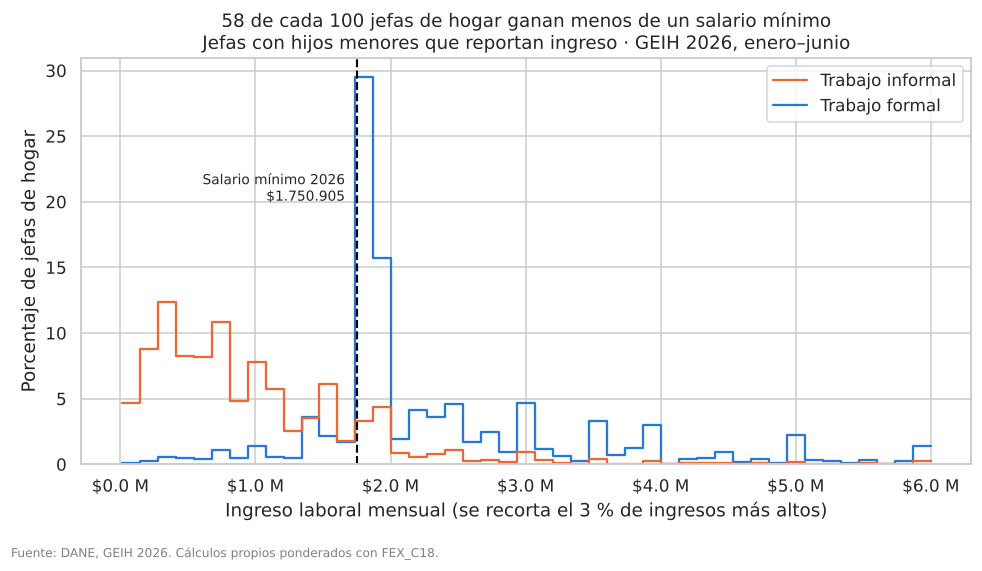

In [8]:
sns.set_theme(style="whitegrid")
ing = ing_jefas.copy()
ing["situacion"] = np.where(ing.informal.eq(1), "Trabajo informal", "Trabajo formal")
tope = ing.INGLABO.quantile(0.97)
visible = ing[ing.INGLABO <= tope]

fig1, ax1 = plt.subplots(figsize=(9, 5))
sns.histplot(data=visible, x="INGLABO", hue="situacion", weights=W, stat="percent",
             common_norm=False, element="step", fill=False, bins=45,
             palette={"Trabajo informal": NARANJA, "Trabajo formal": AZUL}, ax=ax1)
ax1.axvline(SMMLV_2026, color="black", ls="--", lw=1.4)
ax1.text(SMMLV_2026 * 0.95, ax1.get_ylim()[1] * 0.72,
         "Salario mínimo 2026\n$1.750.905", fontsize=9, ha="right", va="top")
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1e6:.1f} M"))
bajo = resumen["jefas_bajo_smmlv_pct"]
ax1.set(xlabel="Ingreso laboral mensual (se recorta el 3 % de ingresos más altos)",
        ylabel="Porcentaje de jefas de hogar",
        title=f"{bajo:.0f} de cada 100 jefas de hogar ganan menos de un salario mínimo\n"
              "Jefas con hijos menores que reportan ingreso · GEIH 2026, enero–junio")
sns.move_legend(ax1, "upper right", title="")
fig1.text(0.01, -0.03, "Fuente: DANE, GEIH 2026. Cálculos propios ponderados con FEX_C18.",
          fontsize=8, color="grey")
fig1.tight_layout()
fig1.savefig(SALIDA / "p3_fig1_ingreso.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Figura 2 (Seaborn): el tipo de empleo y la zona

**Aporte propio.** El dashboard cruza región con posición ocupacional; aquí se cruza
posición con zona, que es donde la diferencia se vuelve más clara para la audiencia.

zona                            Rural  Urbana
posicion                                     
Cuenta propia                    94.0    76.6
Empleado(a) del gobierno          NaN     0.0
Empleado(a) doméstico(a)         94.4    85.7
Empleado(a) particular           57.2    26.1
Jornalero(a) o peón              88.2    69.5
Patrón(a) o empleador(a)          NaN    34.0
Trabajador(a) sin remuneración    NaN   100.0


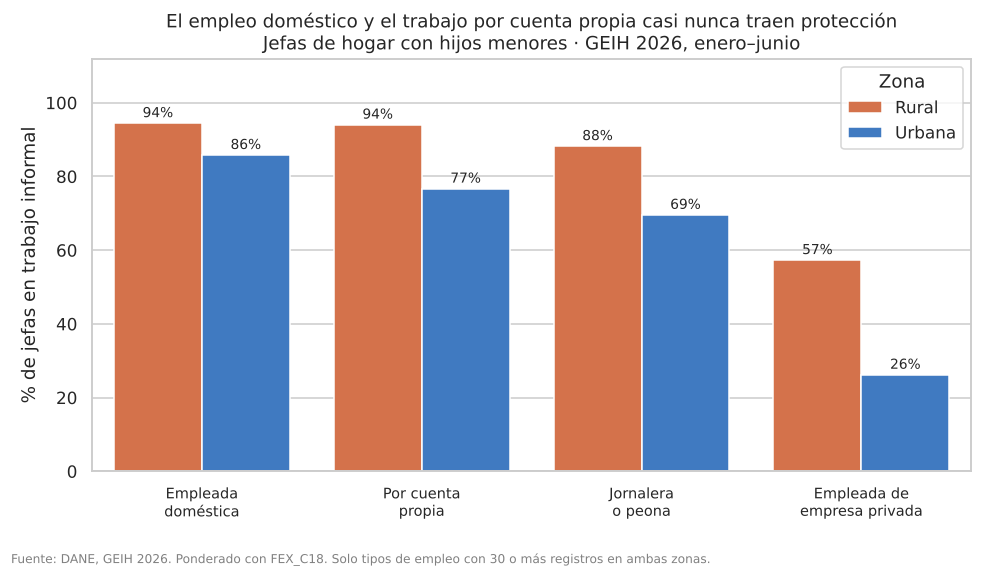

In [9]:
filas = []
for (pos, zona), d in jefas.groupby(["posicion", "zona"]):
    if len(d) >= MIN_CASOS:
        filas.append({"posicion": pos, "zona": zona, "informalidad": tasa(d),
                      "jefas_mes": personas_mes(d), "n": len(d)})
tabla_pos = pd.DataFrame(filas)
tabla_pos.round(4).to_csv(SALIDA / "p3_posicion_zona.csv", index=False, encoding="utf-8")

# Para comparar zonas se dejan solo los tipos de empleo que tienen ambas con muestra
# suficiente. Quedan fuera: "trabajador(a) sin remuneración" (informal por definición, así que
# su 100 % no informa nada), y "empleada del gobierno" y "patrona", sin casos rurales bastantes.
ambas = tabla_pos.groupby("posicion").zona.nunique().pipe(lambda s: s[s == 2].index)
comparables = tabla_pos[tabla_pos.posicion.isin(ambas)]

ETIQUETAS = {"Cuenta propia": "Por cuenta\npropia",
             "Empleado(a) doméstico(a)": "Empleada\ndoméstica",
             "Empleado(a) particular": "Empleada de\nempresa privada",
             "Jornalero(a) o peón": "Jornalera\no peona"}
orden = (comparables.groupby("posicion").informalidad.mean()
         .sort_values(ascending=False).index.tolist())
etiquetas = [ETIQUETAS.get(p, p) for p in orden]

fig2, ax2 = plt.subplots(figsize=(9, 5))
sns.barplot(data=comparables, x="posicion", y="informalidad", hue="zona", order=orden,
            palette={"Urbana": AZUL, "Rural": NARANJA}, errorbar=None, ax=ax2)
for c in ax2.containers:
    ax2.bar_label(c, fmt="%.0f%%", fontsize=9, padding=2)
ax2.set_xticks(range(len(orden)))
ax2.set_xticklabels(etiquetas, fontsize=9.5)
ax2.set(xlabel="", ylabel="% de jefas en trabajo informal", ylim=(0, 112),
        title="El empleo doméstico y el trabajo por cuenta propia casi nunca traen protección\n"
              "Jefas de hogar con hijos menores · GEIH 2026, enero–junio")
sns.move_legend(ax2, "upper right", title="Zona")
fig2.text(0.01, -0.04,
          f"Fuente: DANE, GEIH 2026. Ponderado con FEX_C18. Solo tipos de empleo con "
          f"{MIN_CASOS} o más registros en ambas zonas.",
          fontsize=8, color="grey")
fig2.tight_layout()
fig2.savefig(SALIDA / "p3_fig2_posicion.png", dpi=200, bbox_inches="tight")
plt.show()
print(tabla_pos.pivot(index="posicion", columns="zona", values="informalidad").round(1).to_string())

## 9. Figura interactiva (Plotly): región y tipo de empleo

In [10]:
filas = []
for (region, pos), d in jefas.groupby(["region", "posicion"]):
    if len(d) >= MIN_CASOS:
        filas.append({"region": region, "posicion": pos, "informalidad": tasa(d),
                      "ingreso": media_ingreso(d), "jefas_mes": personas_mes(d),
                      "n": len(d)})
tabla_int = pd.DataFrame(filas)
tabla_int.round(4).to_csv(SALIDA / "p3_region_posicion.csv", index=False, encoding="utf-8")

try:
    import plotly.express as px
    fig3 = px.bar(tabla_int.sort_values("informalidad"), x="informalidad", y="region",
                  color="posicion", barmode="group", orientation="h",
                  hover_data={"ingreso": ":,.0f", "jefas_mes": ":,.0f", "n": True},
                  labels={"informalidad": "% en trabajo informal", "region": "",
                          "posicion": "Tipo de empleo"},
                  title="Informalidad de las jefas de hogar por región y tipo de empleo")
    fig3.update_layout(height=640, legend_title_text="", xaxis_range=[0, 100])
    fig3.write_html(SALIDA / "p3_interactivo.html", include_plotlyjs="cdn")
    fig3.show()
except ImportError:
    print("Plotly no está instalado. Ejecute: pip install plotly")

Plotly no está instalado. Ejecute: pip install plotly


## 10. Control de calidad: ¿coincide con Power BI?

Valores tomados del modelo del Proyecto 1 mediante consultas DAX. Si alguna diferencia
supera la tolerancia, la celda falla.

In [11]:
ESPERADO_PBI = {
    "informalidad_total_pct": 54.9179,
    "informalidad_jefas_pct": 53.6120,
    "informalidad_jefes_pct": 51.8019,
    "jefas_ocupadas_mes": 2_263_844.71,
    "jefas_informales_mes": 1_213_691.82,
    "ingreso_medio_jefas": 1_995_231.60,
    "ingreso_medio_jefes": 2_679_827.99,
    "brecha_ingresos_pct": 25.5463,
    "jefas_bajo_smmlv_pct": 57.7165,
    "casos_jefas": 17_374,
}
REGIONES_PBI = {"Pacífica": 67.9977, "Caribe": 67.4837, "Central": 51.8049,
                "Oriental": 50.0226, "Orinoquía-Amazonía": 49.1101, "Bogotá": 29.3783}

print(f"{'indicador':30} {'Python':>16} {'Power BI':>16} {'dif.':>10}")
fallos = []
for k, esperado in ESPERADO_PBI.items():
    obtenido = resumen[k]
    dif = obtenido - esperado
    tol = max(abs(esperado) * 1e-4, 0.01)
    if abs(dif) > tol:
        fallos.append(k)
    print(f"{k:30} {obtenido:>16,.4f} {esperado:>16,.4f} {dif:>10,.4f}")

print()
for region, esperado in REGIONES_PBI.items():
    obtenido = float(por_region.loc[por_region.region == region, "informalidad_jefas"].iloc[0])
    dif = obtenido - esperado
    if abs(dif) > 0.01:
        fallos.append(region)
    print(f"{region:30} {obtenido:>16.4f} {esperado:>16.4f} {dif:>10.4f}")

assert not fallos, f"No coinciden con Power BI: {fallos}"
print("\nTodas las cifras coinciden con el dashboard de Power BI.")

indicador                                Python         Power BI       dif.
informalidad_total_pct                  54.9179          54.9179     0.0000
informalidad_jefas_pct                  53.6120          53.6120    -0.0000
informalidad_jefes_pct                  51.8019          51.8019    -0.0000
jefas_ocupadas_mes               2,263,844.7059   2,263,844.7100    -0.0041
jefas_informales_mes             1,213,691.8188   1,213,691.8200    -0.0012
ingreso_medio_jefas              1,995,231.6001   1,995,231.6000     0.0001
ingreso_medio_jefes              2,679,827.9852   2,679,827.9900    -0.0048
brecha_ingresos_pct                     25.5463          25.5463    -0.0000
jefas_bajo_smmlv_pct                    57.7165          57.7165     0.0000
casos_jefas                         17,374.0000      17,374.0000     0.0000

Pacífica                                67.9977          67.9977    -0.0000
Caribe                                  67.4837          67.4837    -0.0000
Central    

## 11. Contraste con la cifra publicada por el DANE
El DANE publicó **54,5 %** de informalidad nacional para el trimestre abril–junio de 2026.

In [12]:
print(f"Informalidad nacional abril–junio: {tasa(trimestre2):.2f}%   (DANE publicó 54,5%)")
print(f"Informalidad nacional enero–junio: {tasa(datos):.2f}%")
print()
print("Archivos generados:", sorted(p.name for p in SALIDA.iterdir()))

Informalidad nacional abril–junio: 54.52%   (DANE publicó 54,5%)
Informalidad nacional enero–junio: 54.92%

Archivos generados: ['p3_fig1_ingreso.png', 'p3_fig2_posicion.png', 'p3_por_region.csv', 'p3_posicion_zona.csv', 'p3_region_posicion.csv', 'p3_resumen_nacional.csv']
